# 01 — Fibra óptica: um efeito por vez

Este notebook verifica o integrador da fibra (`simcopy.kernels.ssfm.propagate`)
contra soluções de forma fechada. A equação completa não tem solução geral; por
isso cada seção zera os termos que não interessam, e o efeito isolado passa a ter
solução exata para comparação. A última seção liga todos os termos e verifica o
que continua tendo resposta exata: a energia e a ordem de convergência.

Regras usadas em todas as figuras:

- a física simulada vem **sempre** do pacote (`propagate`); o notebook só escreve a
  forma fechada, que é a referência;
- forma fechada (linha) e simulação (pontos) no mesmo painel, um parâmetro variado
  por vez, e o erro em painel próprio;
- as asserções numéricas ficam nos testes do pytest; cada seção indica qual teste
  garante o resultado mostrado.

Fonte das formas fechadas: Agrawal, *Nonlinear Fiber Optics* (NLFO), cap. 2 a 5, e
*Sistemas de Comunicação por Fibra Óptica*, cap. 2.

## 0. Equação e termos

O envelope lento $\mathbf{A} = (A_x, A_y)$ obedece à equação de Manakov:

$$
\frac{\partial \mathbf{A}}{\partial z} =
\underbrace{-\frac{\alpha}{2}\mathbf{A}}_{\text{atenuação}}
\;\underbrace{-\;\frac{i\beta_2}{2}\frac{\partial^2 \mathbf{A}}{\partial T^2}}_{\text{dispersão}}
\;+\;\underbrace{i\gamma\,\tfrac{8}{9}\left(|A_x|^2+|A_y|^2\right)\mathbf{A}}_{\text{Kerr}}
\;+\;\underbrace{\text{PMD}}_{\text{birrefringência aleatória}}
$$

Com uma polarização só e sem o fator 8/9, ela se reduz à equação não linear de
Schrödinger (NLSE) escalar. O fator 8/9 vem da média da não linearidade sobre a
rotação rápida do estado de polarização (decisão D-2: o pipeline usa sempre Manakov;
a NLSE escalar aparece só quando a comparação é com uma forma fechada escalar).

| Seção | α | β₂ | γ | PMD | Forma fechada |
|---|---|---|---|---|---|
| 1 propagação | 0 | 0 | 0 | 0 | saída = entrada |
| 2 atenuação | ✓ | 0 | 0 | 0 | $P(z) = P_0 e^{-\alpha z}$ |
| 3 dispersão | 0 | ✓ | 0 | 0 | gaussiana com chirp; fase espectral $\beta_2\omega^2 z/2$ |
| 4 PMD | 0 | 0 | 0 | ✓ | $\lVert\mathbf{S}\rVert = 1$ por frequência (rotação unitária) |
| 5 Kerr | ✓/0 | 0/✓ | ✓ | 0 | SPM; sóliton; FWM em pequeno sinal |
| 6 tudo junto | ✓ | ✓ | ✓ | ✓ | energia $e^{-\alpha L}$; erro $\propto h^2$ |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from simcopy.core.grid import TimeGrid
from simcopy.core.units import (beta2_from_dispersion, gamma_from_n2,
                                db_per_m_to_np_per_m, frequency_to_wavelength)
from simcopy.kernels.ssfm import propagate, FiberKernelParams

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "legend.fontsize": 7.5})
C3 = ["tab:blue", "tab:orange", "tab:green"]
C4 = C3 + ["tab:red"]

# Fibra de referência (valores típicos, Agrawal): todas as seções partem destes valores
# e zeram o que não interessa.
F0 = 193.1e12                                   # Hz, âncora da grade ITU
LAM = frequency_to_wavelength(F0)               # m, λ = c/f
D = 16e-6                                       # s/m² = 16 ps/(nm·km)
B2 = beta2_from_dispersion(D, LAM)              # s²/m (negativo: dispersão anômala)
GAMMA = gamma_from_n2(2.6e-20, 80e-12, LAM)     # 1/(W·m)
ALPHA = db_per_m_to_np_per_m(0.2e-3)            # Np/m = 0,2 dB/km
print(f"λ = {LAM*1e9:.3f} nm | β₂ = {B2*1e27:.2f} ps²/km | "
      f"γ = {GAMMA*1e3:.3f} 1/(W·km) | α = {ALPHA*1e3:.4f} Np/km")

def grade(N, fs):
    """Grade do pacote, com t = 0 no centro da janela."""
    g = TimeGrid(sampling_rate=fs, n_samples=N, t0=-(N // 2) / fs)
    return g.time, g.freq, g.omega

def fibra(L, beta2=0.0, gamma=0.0, alpha=0.0, **kw):
    return FiberKernelParams(length=L, beta2=beta2, gamma=gamma, alpha_np=alpha, **kw)

def erro(ref, sim):
    """Erro relativo no campo complexo: captura amplitude e fase juntas."""
    return np.max(np.abs(sim - ref)) / np.max(np.abs(ref))

def energia(A, dt):
    return np.sum(np.abs(A) ** 2) * dt

def eixo_log_legivel(a, ticks):
    """Eixo x logarítmico com rótulos só nos valores dados."""
    from matplotlib.ticker import FixedLocator, NullLocator, ScalarFormatter
    a.xaxis.set_major_locator(FixedLocator(ticks))
    a.xaxis.set_major_formatter(ScalarFormatter())
    a.xaxis.set_minor_locator(NullLocator())

def gaussiana(t, T0, P0=1.0, C=0.0):
    """A(0,T) = √P0 · exp[-(1 + iC) T² / (2 T0²)]  (NLFO, 3.2)."""
    return np.sqrt(P0) * np.exp(-(1 + 1j * C) * t ** 2 / (2 * T0 ** 2))

λ = 1552.524 nm | β₂ = -20.47 ps²/km | γ = 1.315 1/(W·km) | α = 0.0461 Np/km


## 1. Propagação sem efeitos: gaussiana e RRC

**Conceito.** Com α = β₂ = γ = 0 a equação se reduz a $\partial\mathbf{A}/\partial z = 0$:
a saída é igual à entrada em qualquer distância. Esse caso não testa física; testa o
encanamento do integrador (FFT, ordem das frequências, meio passo linear duas vezes).
Qualquer erro aqui contaminaria todas as seções seguintes.

Dois formatos de pulso: a gaussiana (usada nas formas fechadas) e o RRC (raiz de
cosseno levantado), que é o formato dos símbolos no transmissor. O RRC é montado
aqui no domínio da frequência, como referência provisória, até o bloco
`PulseShaper` do transmissor existir.

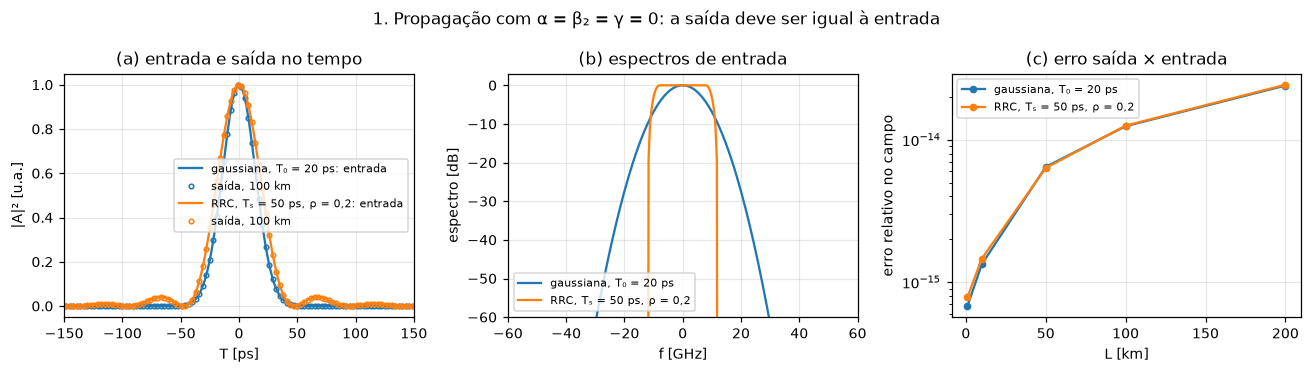

In [2]:
N, FS = 2 ** 12, 2e12                       # dt = 0,5 ps; janela de 2,05 ns
t, f, om = grade(N, FS)
T0 = 20e-12

def rrc(f, Ts, rho):
    """Pulso RRC com roll-off rho: raiz do espectro de cosseno levantado, centrado em t = 0."""
    af = np.abs(f)
    f1, f2 = (1 - rho) / (2 * Ts), (1 + rho) / (2 * Ts)
    H = np.where(af <= f1, 1.0, 0.0)
    banda = (af > f1) & (af <= f2)
    H[banda] = 0.5 * (1 + np.cos(np.pi * Ts / rho * (af[banda] - f1)))
    p = np.fft.fftshift(np.fft.ifft(np.sqrt(H)))
    return (p / np.abs(p).max()).astype(complex)

pulsos = {"gaussiana, T₀ = 20 ps": gaussiana(t, T0),
          "RRC, Tₛ = 50 ps, ρ = 0,2": rrc(f, 50e-12, 0.2)}
Ls = np.array([1e3, 10e3, 50e3, 100e3, 200e3])

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for i, (nome, A0) in enumerate(pulsos.items()):
    saida = propagate(A0[None, :], om, fibra(100e3))[0]
    ax[0].plot(t * 1e12, np.abs(A0) ** 2, "-", color=C3[i], label=f"{nome}: entrada")
    ax[0].plot(t[::6] * 1e12, np.abs(saida[::6]) ** 2, "o", ms=3, mfc="none",
               color=C3[i], label="saída, 100 km")
    S = np.fft.fftshift(np.abs(np.fft.fft(A0)) ** 2)
    ax[1].plot(np.fft.fftshift(f) / 1e9, 10 * np.log10(S / S.max() + 1e-30), color=C3[i],
               label=nome)
    ax[2].semilogy(Ls / 1e3, [erro(A0, propagate(A0[None, :], om, fibra(L))[0]) + 1e-18
                              for L in Ls], "o-", ms=4, color=C3[i], label=nome)
ax[0].set(xlim=(-150, 150), xlabel="T [ps]", ylabel="|A|² [u.a.]",
          title="(a) entrada e saída no tempo")
ax[1].set(xlim=(-60, 60), ylim=(-60, 3), xlabel="f [GHz]", ylabel="espectro [dB]",
          title="(b) espectros de entrada")
ax[2].set(xlabel="L [km]", ylabel="erro relativo no campo", title="(c) erro saída × entrada")
for a in ax: a.legend()
fig.suptitle("1. Propagação com α = β₂ = γ = 0: a saída deve ser igual à entrada")
fig.tight_layout()

**Leitura.** Cada passo (FFT, multiplicação, FFT inversa) acrescenta um erro de
arredondamento da ordem de 1e-16, que é a precisão dupla. O erro em (c) cresce com o
número de passos (um a cada 5 km) e chega a ~1e-14 em 200 km: é acúmulo de
arredondamento, não física. O RRC tem espectro limitado em
$(1+\rho)/(2T_s) = 12$ GHz e oscilações no tempo (os cruzamentos por zero a cada
$T_s$ são o que zera a interferência entre símbolos depois do filtro casado).

## 2. Atenuação

**Equação** (β₂ = γ = 0): $\partial A/\partial z = -\tfrac{\alpha}{2}A$, com solução
$A(z,T) = A(0,T)\,e^{-\alpha z/2}$. A potência cai como $P(z) = P_0 e^{-\alpha z}$ e a
forma do pulso não muda. Em decibéis a queda é linear: 0,2 dB/km dá 20 dB em 100 km.

Unidades do pacote: atenuação em dB/m na configuração; o kernel recebe α em Np/m
($\alpha_{Np} = \alpha_{dB}\,\ln 10 / 10$).

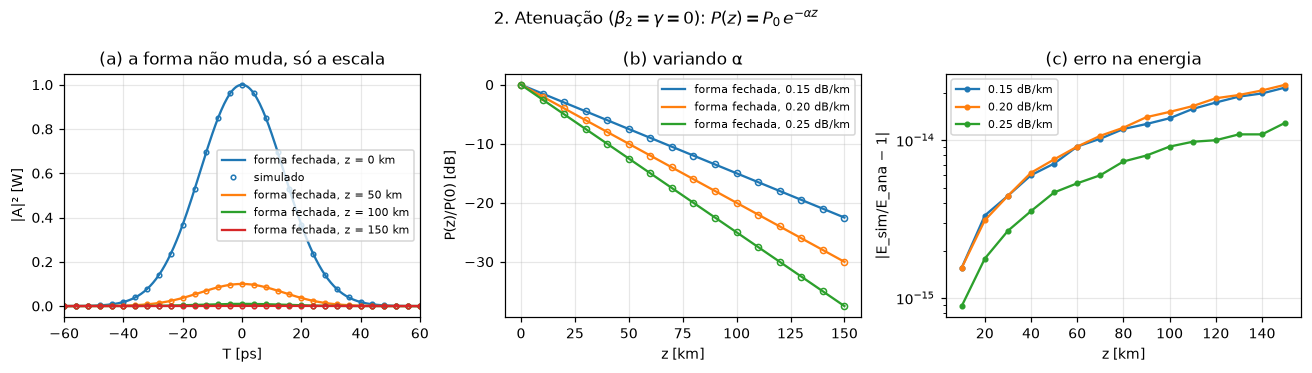

In [3]:
A0 = gaussiana(t, T0)
dt = 1 / FS
zs = np.linspace(0, 150e3, 16)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for i, z in enumerate([0, 50e3, 100e3, 150e3]):
    s = propagate(A0[None, :], om, fibra(z, alpha=ALPHA))[0]
    ax[0].plot(t * 1e12, np.abs(A0 * np.exp(-ALPHA * z / 2)) ** 2, "-", color=C4[i],
               label=f"forma fechada, z = {z/1e3:.0f} km")
    ax[0].plot(t[::8] * 1e12, np.abs(s[::8]) ** 2, "o", ms=3, mfc="none", color=C4[i],
               label="simulado" if i == 0 else None)
for i, adb in enumerate([0.15e-3, 0.20e-3, 0.25e-3]):
    a = db_per_m_to_np_per_m(adb)
    E = np.array([energia(propagate(A0[None, :], om, fibra(z, alpha=a))[0], dt) for z in zs])
    E_ana = energia(A0, dt) * np.exp(-a * zs)
    ax[1].plot(zs / 1e3, 10 * np.log10(E_ana / E_ana[0]), "-", color=C3[i],
               label=f"forma fechada, {adb*1e3:.2f} dB/km")
    ax[1].plot(zs / 1e3, 10 * np.log10(E / E[0]), "o", ms=4, mfc="none", color=C3[i])
    ax[2].semilogy(zs[1:] / 1e3, np.abs(E[1:] / E_ana[1:] - 1) + 1e-18, "o-", ms=3,
                   color=C3[i], label=f"{adb*1e3:.2f} dB/km")
ax[0].set(xlim=(-60, 60), xlabel="T [ps]", ylabel="|A|² [W]",
          title="(a) a forma não muda, só a escala")
ax[1].set(xlabel="z [km]", ylabel="P(z)/P(0) [dB]", title="(b) variando α")
ax[2].set(xlabel="z [km]", ylabel="|E_sim/E_ana − 1|", title="(c) erro na energia")
for a_ in ax: a_.legend()
fig.suptitle(r"2. Atenuação ($\beta_2 = \gamma = 0$): $P(z) = P_0\,e^{-\alpha z}$")
fig.tight_layout()

**Leitura.** As retas em (b) têm inclinação igual ao coeficiente em dB/km, e o erro em
(c) fica no arredondamento. O operador linear aplica $e^{-\alpha\,dz/4}$ em cada meio
passo (duas vezes por passo, sobre o campo), o que dá exatamente $e^{-\alpha z/2}$ no
campo para qualquer tamanho de passo.

Teste que garante: `test_01_atenuacao.py` (inclui comprimento que não é múltiplo do
passo, o bug 3 do histórico).

## 3. Dispersão cromática

**Equação** (α = γ = 0): $\partial A/\partial z = -\tfrac{i\beta_2}{2}\,\partial^2 A/\partial T^2$.
No domínio da frequência cada componente só ganha fase:
$\tilde A(z,\omega) = \tilde A(0,\omega)\,e^{\,i\beta_2\omega^2 z/2}$. Dessa forma o
módulo do espectro não muda; o que muda é a fase espectral, quadrática em ω, e é ela
que alarga o pulso no tempo (componentes de frequências diferentes chegam em tempos
diferentes).

**Forma fechada** (NLFO, 3.2) para a gaussiana com chirp inicial C:

$$A(z,T) = \sqrt{\frac{T_0^2}{q}}\exp\!\left[-\frac{(1+iC)\,T^2}{2q}\right],\qquad
q = T_0^2 - i\beta_2 z\,(1+iC)$$

$$\frac{T_1}{T_0} = \sqrt{\left(1+\frac{C\beta_2 z}{T_0^2}\right)^2+\left(\frac{\beta_2 z}{T_0^2}\right)^2},
\qquad L_D = \frac{T_0^2}{|\beta_2|}$$

Com $C\beta_2 < 0$ o pulso primeiro comprime e depois alarga. Esse caso existe no
teste porque o alargamento sem chirp depende só de $|\beta_2|$: um erro de sinal na
dispersão passaria despercebido sem ele.

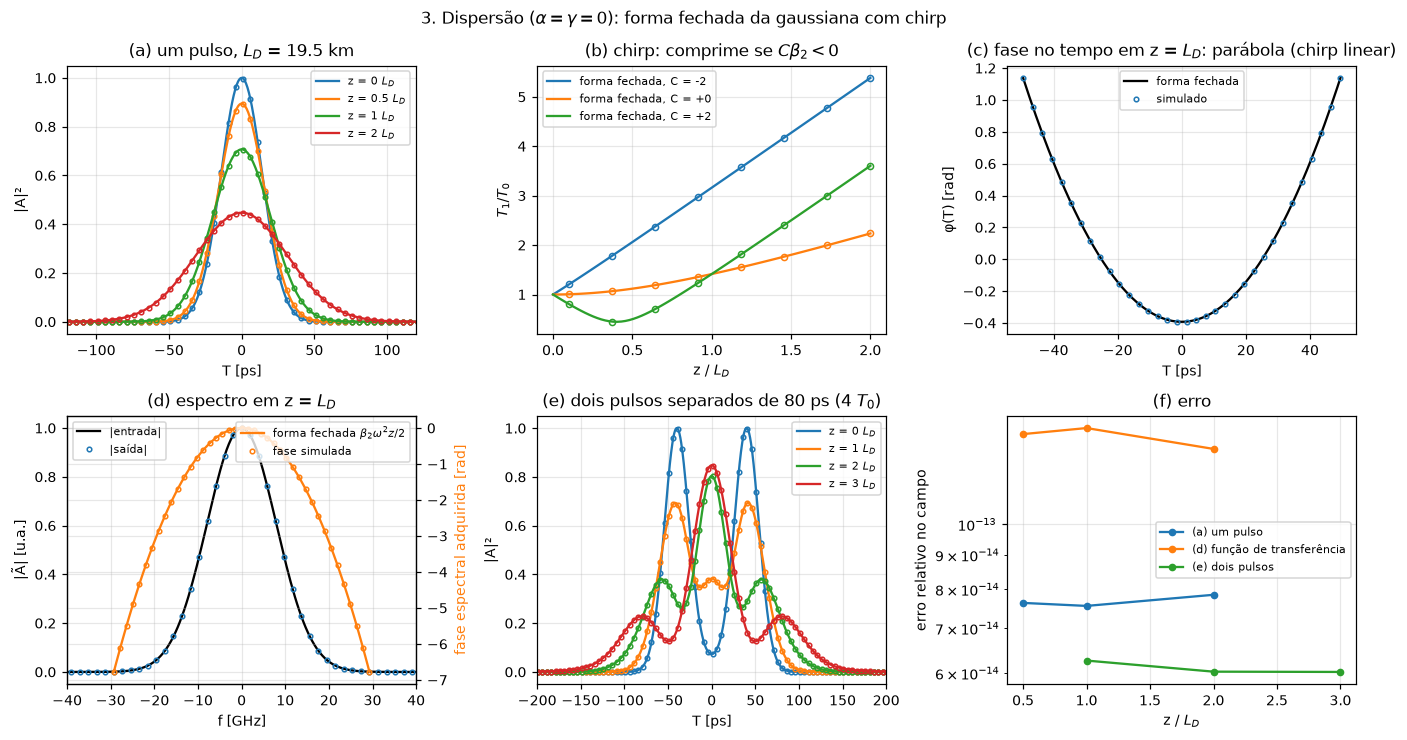

In [4]:
def gauss_ana(T, T0, z, b2, C=0.0):
    q = T0 ** 2 - 1j * b2 * z * (1 + 1j * C)
    return np.sqrt(T0 ** 2 / q) * np.exp(-(1 + 1j * C) * T ** 2 / (2 * q))

def largura(t, A):
    """T1 a partir da largura rms da intensidade: para gaussiana, T1 = √2·σ."""
    I = np.abs(A) ** 2
    tc = np.sum(I * t) / np.sum(I)
    return np.sqrt(2 * np.sum(I * (t - tc) ** 2) / np.sum(I))

LD = T0 ** 2 / abs(B2)
sim = lambda A, z: propagate(A[None, :], om, fibra(z, beta2=B2), max_step=max(z, 1) / 200)[0]

fig, ax = plt.subplots(2, 3, figsize=(12.5, 6.8))
erros = {}
# (a) perfis de um pulso em várias distâncias
for i, zr in enumerate([0, 0.5, 1, 2]):
    a, s = gauss_ana(t, T0, zr * LD, B2), sim(gaussiana(t, T0), zr * LD)
    ax[0, 0].plot(t * 1e12, np.abs(a) ** 2, "-", color=C4[i], label=f"z = {zr} $L_D$")
    ax[0, 0].plot(t[::10] * 1e12, np.abs(s[::10]) ** 2, "o", ms=3, mfc="none", color=C4[i])
    if zr > 0:
        erros.setdefault("(a) um pulso", []).append((zr, erro(a, s)))
ax[0, 0].set(xlim=(-120, 120), xlabel="T [ps]", ylabel="|A|²",
             title=f"(a) um pulso, $L_D$ = {LD/1e3:.1f} km")
# (b) largura × distância variando o chirp
zz = np.linspace(0, 2, 80) * LD
zp = np.linspace(0.1, 2, 8) * LD
for i, C in enumerate([-2.0, 0.0, 2.0]):
    ana = np.sqrt((1 + C * B2 * zz / T0 ** 2) ** 2 + (B2 * zz / T0 ** 2) ** 2)
    ax[0, 1].plot(zz / LD, ana, "-", color=C3[i], label=f"forma fechada, C = {C:+.0f}")
    ax[0, 1].plot(zp / LD, [largura(t, sim(gaussiana(t, T0, C=C), z)) / T0 for z in zp],
                  "o", ms=4, mfc="none", color=C3[i])
ax[0, 1].set(xlabel="z / $L_D$", ylabel="$T_1/T_0$",
             title=r"(b) chirp: comprime se $C\beta_2 < 0$")
# (c) fase no tempo em z = L_D
a, s = gauss_ana(t, T0, LD, B2), sim(gaussiana(t, T0), LD)
janela = np.abs(t) < 2.5 * T0
ax[0, 2].plot(t[janela] * 1e12, np.unwrap(np.angle(a[janela])), "-", color="k",
              label="forma fechada")
ax[0, 2].plot(t[janela][::6] * 1e12, np.unwrap(np.angle(s[janela]))[::6], "o", ms=3,
              mfc="none", color=C3[0], label="simulado")
ax[0, 2].set(xlabel="T [ps]", ylabel="φ(T) [rad]",
             title="(c) fase no tempo em z = $L_D$: parábola (chirp linear)")
# (d) espectro: módulo igual, fase quadrática
z = LD
Sin, Sout = np.fft.fft(gaussiana(t, T0)), np.fft.fft(sim(gaussiana(t, T0), z))
k = np.argsort(f)
banda = np.abs(Sin[k]) > 1e-3 * np.abs(Sin).max()
ax[1, 0].plot(f[k] / 1e9, np.abs(Sin[k]) / np.abs(Sin).max(), "-", color="k", label="|entrada|")
ax[1, 0].plot(f[k][::4] / 1e9, np.abs(Sout[k][::4]) / np.abs(Sin).max(), "o", ms=3,
              mfc="none", color=C3[0], label="|saída|")
ax2 = ax[1, 0].twinx()
ax2.plot(f[k][banda] / 1e9, 0.5 * B2 * om[k][banda] ** 2 * z, "-", color=C3[1],
         label=r"forma fechada $\beta_2\omega^2 z/2$")
fase = np.unwrap(np.angle(Sout[k][banda] / Sin[k][banda]))
centro = np.argmin(np.abs(f[k][banda]))           # ancora o unwrap em f = 0 (fase 0 lá)
fase -= 2 * np.pi * np.round(fase[centro] / (2 * np.pi))
ax2.plot(f[k][banda][::3] / 1e9, fase[::3], "o", ms=3, mfc="none", color=C3[1],
         label="fase simulada")
ax2.set_ylabel("fase espectral adquirida [rad]", color=C3[1])
ax[1, 0].set(xlim=(-40, 40), xlabel="f [GHz]", ylabel="|Ã| [u.a.]",
             title="(d) espectro em z = $L_D$")
ax2.legend(loc="upper right")
erros["(d) função de transferência"] = [
    (zr, np.max(np.abs(np.fft.fft(sim(gaussiana(t, T0), zr * LD))
                       - Sin * np.exp(0.5j * B2 * om ** 2 * zr * LD))) / np.abs(Sin).max())
    for zr in [0.5, 1, 2]]
# (e) dois pulsos com o mesmo λ: alargam e passam a se sobrepor
sep = 4 * T0
dois = lambda z: (gauss_ana(t - sep / 2, T0, z, B2) + gauss_ana(t + sep / 2, T0, z, B2))
for i, zr in enumerate([0, 1, 2, 3]):
    a, s = dois(zr * LD), sim(dois(0), zr * LD)
    ax[1, 1].plot(t * 1e12, np.abs(a) ** 2, "-", color=C4[i], label=f"z = {zr} $L_D$")
    ax[1, 1].plot(t[::10] * 1e12, np.abs(s[::10]) ** 2, "o", ms=3, mfc="none", color=C4[i])
    if zr > 0:
        erros.setdefault("(e) dois pulsos", []).append((zr, erro(a, s)))
ax[1, 1].set(xlim=(-200, 200), xlabel="T [ps]", ylabel="|A|²",
             title=f"(e) dois pulsos separados de {sep*1e12:.0f} ps (4 $T_0$)")
# (f) erro
for i, (nome, pts) in enumerate(erros.items()):
    zr, e = zip(*pts)
    ax[1, 2].semilogy(zr, np.array(e) + 1e-18, "o-", ms=4, color=C3[i], label=nome)
ax[1, 2].set(xlabel="z / $L_D$", ylabel="erro relativo no campo", title="(f) erro")
for a_ in [ax[0, 0], ax[0, 1], ax[0, 2], ax[1, 1], ax[1, 2]]: a_.legend()
ax[1, 0].legend(loc="upper left")
fig.suptitle(r"3. Dispersão ($\alpha = \gamma = 0$): forma fechada da gaussiana com chirp")
fig.tight_layout()

**Leitura.**
- (b) Só o sinal de β₂ do pacote (negativo para D > 0) faz C = +2 comprimir; com o sinal
  trocado, as curvas de C = +2 e C = −2 trocariam de lugar.
- (c) A fase no tempo é parabólica: a frequência instantânea varia linearmente ao longo
  do pulso, que é o chirp induzido pela dispersão.
- (d) O módulo do espectro não muda e a fase adquirida é $\beta_2\omega^2 z/2$; o erro da
  função de transferência inteira está em (f).
- (e) Os dois pulsos começam separados e, ao alargar, passam a se sobrepor. Na região
  de sobreposição os campos se somam com fases diferentes (cada pulso tem o próprio
  chirp), e a intensidade deixa de ser a soma das intensidades. A forma fechada é a
  soma dos dois campos, porque a equação é linear quando γ = 0. Essa sobreposição é a
  interferência entre símbolos que a compensação de dispersão do receptor precisa desfazer.

Teste que garante: `test_02_dispersao.py` (largura, chirp e o sinal de β₂).

## 4. PMD: estado de polarização na esfera de Poincaré

**Conceito.** A birrefringência da fibra varia aleatoriamente ao longo do comprimento.
O pacote modela a fibra como uma sequência de seções de comprimento $L_{corr}$: em cada
fronteira o estado de polarização sofre uma rotação aleatória uniforme (matriz de SU(2))
e, dentro de cada passo, as duas polarizações principais ganham um atraso diferencial
(DGD). Como a rotação é unitária, cada componente de frequência continua totalmente
polarizada: o vetor de Stokes normalizado tem módulo 1. Como o DGD multiplica a
frequência, componentes de frequências diferentes saem com estados diferentes.

Vetor de Stokes (normalizado por $S_0 = |X|^2+|Y|^2$):
$S_1 = |X|^2-|Y|^2$, $S_2 = 2\,\mathrm{Re}(XY^*)$, $S_3 = -2\,\mathrm{Im}(XY^*)$
(o sinal de $S_3$ varia entre autores).

**Todas as entradas precisam ser vetoriais para PMD:** `propagate` só aplica PMD se o
campo tiver duas polarizações, forma (2, N). Com forma (1, N) a PMD é ignorada sem aviso
(verificado na primeira célula abaixo).

**Evolução ao longo de z.** `propagate` devolve só o campo no fim da fibra. Sem não
linearidade o passo é fixo; propagar até cada $z_k$ (múltiplo do passo) com a mesma seed
repete a mesma sequência de passos e de sorteios, e portanto reproduz o início da mesma
realização. Uma opção do kernel para devolver o campo em posições escolhidas tornaria
isso direto (decisão pendente).

campo (1, N): erro saída × entrada = 1.2750230063848771e-14 → a PMD não foi aplicada


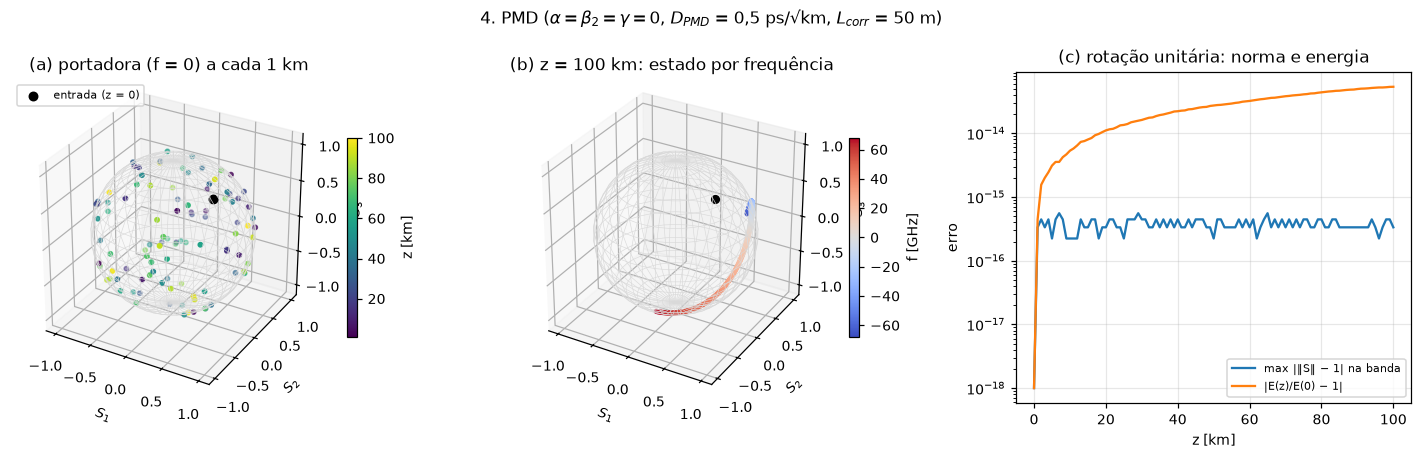

In [5]:
T0p, DPMD, PASSO = 5e-12, 0.5e-12 / np.sqrt(1e3), 1e3   # 0,5 ps/√km: exagerado para visualização
Ap = gaussiana(t, T0p)
entrada = np.vstack([Ap, Ap]) / np.sqrt(2)               # linear a 45°
pmd = lambda z: fibra(z, pmd_coefficient=DPMD, correlation_length=50.0)
rodar = lambda z, seed=7: propagate(entrada, om, pmd(z), rng=np.random.default_rng(seed),
                                    max_step=PASSO)

escalar = propagate(Ap[None, :] / np.sqrt(2), om, pmd(100e3), rng=np.random.default_rng(7))
print("campo (1, N): erro saída × entrada =", erro(Ap / np.sqrt(2), escalar[0]),
      "→ a PMD não foi aplicada")

def stokes(X, Y):
    S0 = np.abs(X) ** 2 + np.abs(Y) ** 2
    return np.array([np.abs(X) ** 2 - np.abs(Y) ** 2, 2 * np.real(X * np.conj(Y)),
                     -2 * np.imag(X * np.conj(Y))]) / S0

zk = np.arange(0, 101e3, PASSO)
saidas = [rodar(z) for z in zk]
Xf = [np.fft.fft(s[0]) for s in saidas]
Yf = [np.fft.fft(s[1]) for s in saidas]
S_portadora = np.array([stokes(X[0], Y[0]) for X, Y in zip(Xf, Yf)])          # f = 0
espectro = np.abs(Xf[-1]) ** 2 + np.abs(Yf[-1]) ** 2
bins = np.where(espectro > 0.01 * espectro.max())[0]
S_freq = stokes(Xf[-1][bins], Yf[-1][bins])
erro_norma = [np.max(np.abs(np.linalg.norm(stokes(X[bins], Y[bins]), axis=0) - 1))
              for X, Y in zip(Xf, Yf)]
erro_energia = [abs(energia(s, dt) / energia(entrada, dt) - 1) for s in saidas]

def esfera(a):
    u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
    a.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v),
                     color="0.85", lw=0.4)
    a.set(xlabel="$S_1$", ylabel="$S_2$", zlabel="$S_3$", box_aspect=(1, 1, 1))

fig = plt.figure(figsize=(13, 4.2))
a1 = fig.add_subplot(1, 3, 1, projection="3d"); esfera(a1)
sz = a1.scatter(*S_portadora[1:].T, c=zk[1:] / 1e3, cmap="viridis", s=8)
a1.scatter(*S_portadora[0], color="k", s=30, label="entrada (z = 0)")
fig.colorbar(sz, ax=a1, shrink=0.6, label="z [km]")
a1.set_title("(a) portadora (f = 0) a cada 1 km")
a1.legend(loc="upper left")
a2 = fig.add_subplot(1, 3, 2, projection="3d"); esfera(a2)
sc = a2.scatter(*S_freq, c=f[bins] / 1e9, cmap="coolwarm", s=6)
a2.scatter(*S_portadora[0], color="k", s=25)
fig.colorbar(sc, ax=a2, shrink=0.6, label="f [GHz]")
a2.set_title("(b) z = 100 km: estado por frequência")
a3 = fig.add_subplot(1, 3, 3)
a3.semilogy(zk / 1e3, np.array(erro_norma) + 1e-18, "-", color=C3[0],
            label="max |‖S‖ − 1| na banda")
a3.semilogy(zk / 1e3, np.array(erro_energia) + 1e-18, "-", color=C3[1],
            label="|E(z)/E(0) − 1|")
a3.set(xlabel="z [km]", ylabel="erro", title="(c) rotação unitária: norma e energia")
a3.legend()
fig.suptitle("4. PMD ($\\alpha = \\beta_2 = \\gamma = 0$, $D_{PMD}$ = 0,5 ps/√km, "
             "$L_{corr}$ = 50 m)")
fig.tight_layout()

**Leitura.**
- (a) A cada 1 km o estado da portadora está em um ponto diferente da superfície da
  esfera: continua totalmente polarizado, mas a orientação não guarda memória da
  anterior. Isso decorre do modelo: cada fronteira de seção sorteia uma rotação
  uniforme e independente, então pontos separados por mais de $L_{corr}$ são
  independentes e cobrem a esfera de modo uniforme (é o que `test_04_pmd.py::test_d`
  verifica). Em escala de quilômetros isso corresponde à fibra real, cujo estado se
  descorrelaciona em dezenas de metros. Abaixo de $L_{corr}$ o modelo não representa a
  evolução contínua do estado: dentro de uma seção a portadora não muda e na fronteira
  salta. Ver a mudança gradual pediria um modelo de birrefringência contínua (pendente).
- (b) Na saída, as frequências do pulso ocupam um arco: com DGD, o estado depende da
  frequência. Na entrada, todas estavam no mesmo ponto (preto). Quanto maior o DGD
  acumulado ou a banda do sinal, maior o arco; por isso a PMD pesa mais em taxas altas.
- (c) Norma de Stokes e energia ficam no arredondamento, o que verifica que rotação e
  DGD são unitários.

A estatística do DGD (média ∝ √z, distribuição maxwelliana, rotação uniforme na esfera)
exige muitas realizações e está nos testes: `test_04_pmd.py`.

## 5. Efeito Kerr

### 5.1 Automodulação de fase (SPM), sem dispersão

**Equação** (β₂ = 0, escalar): $\partial A/\partial z = -\tfrac{\alpha}{2}A + i\gamma|A|^2A$.
Sem dispersão a intensidade de cada instante só decai com α, e a fase cresce com a
própria intensidade:

$$A(L,T) = A(0,T)\,e^{-\alpha L/2}\exp\!\left[i\gamma|A(0,T)|^2 L_{eff}\right],
\qquad L_{eff} = \frac{1-e^{-\alpha L}}{\alpha}$$

A fase não linear tem a forma do pulso. Dobrar a amplitude quadruplica a potência e,
portanto, a fase. A forma do pulso no tempo não muda; o espectro alarga, porque a fase
variável no tempo cria frequências novas (frequência instantânea $\propto \partial\phi/\partial T$).

Manakov DP (mesma potência total): φ_max/φ_max escalar = 0.888889  (esperado 8/9 = 0.888889)


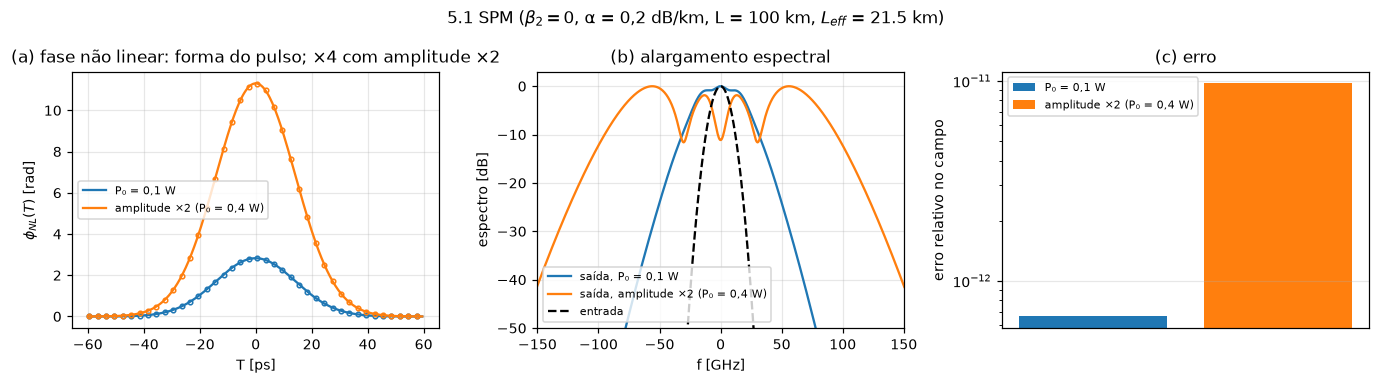

In [6]:
L5 = 100e3
Leff = (1 - np.exp(-ALPHA * L5)) / ALPHA
spm = fibra(L5, gamma=GAMMA, alpha=ALPHA, manakov=False)
casos = {"P₀ = 0,1 W": 0.1, "amplitude ×2 (P₀ = 0,4 W)": 0.4}
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.5))
saida_spm = {}
for i, (nome, P0) in enumerate(casos.items()):
    A0 = gaussiana(t, T0, P0)
    a = A0 * np.exp(-ALPHA * L5 / 2) * np.exp(1j * GAMMA * np.abs(A0) ** 2 * Leff)
    s = propagate(A0[None, :], om, spm)[0]
    saida_spm[nome] = s
    jan = np.abs(t) < 3 * T0
    ax[0].plot(t[jan] * 1e12, GAMMA * np.abs(A0[jan]) ** 2 * Leff, "-", color=C3[i],
               label=nome)
    ax[0].plot(t[jan][::6] * 1e12, np.unwrap(np.angle(s[jan] / A0[jan]))[::6], "o", ms=3,
               mfc="none", color=C3[i])
    Sin = np.fft.fftshift(np.abs(np.fft.fft(A0)) ** 2)
    Sout = np.fft.fftshift(np.abs(np.fft.fft(s)) ** 2)
    ax[1].plot(np.fft.fftshift(f) / 1e9, 10 * np.log10(Sout / Sout.max() + 1e-30), "-",
               color=C3[i], label=f"saída, {nome}")
    ax[2].bar(i, erro(a, s), color=C3[i], label=nome)
ax[1].plot(np.fft.fftshift(f) / 1e9, 10 * np.log10(Sin / Sin.max() + 1e-30), "k--",
           label="entrada")
DP = propagate(np.vstack([gaussiana(t, T0, 0.1)] * 2) / np.sqrt(2), om,
               fibra(L5, gamma=GAMMA, alpha=ALPHA, manakov=True))
fase_dp = np.angle(DP[0][N // 2] / (gaussiana(t, T0, 0.1)[N // 2] / np.sqrt(2)
                                    * np.exp(-ALPHA * L5 / 2)))
print(f"Manakov DP (mesma potência total): φ_max/φ_max escalar = "
      f"{fase_dp / (GAMMA * 0.1 * Leff):.6f}  (esperado 8/9 = {8/9:.6f})")
ax[0].set(xlabel="T [ps]", ylabel=r"$\phi_{NL}(T)$ [rad]",
          title=r"(a) fase não linear: forma do pulso; ×4 com amplitude ×2")
ax[1].set(xlim=(-150, 150), ylim=(-50, 3), xlabel="f [GHz]", ylabel="espectro [dB]",
          title="(b) alargamento espectral")
ax[2].set(yscale="log", xticks=[], ylabel="erro relativo no campo", title="(c) erro")
for a_ in ax: a_.legend()
fig.suptitle(rf"5.1 SPM ($\beta_2 = 0$, α = 0,2 dB/km, L = 100 km, $L_{{eff}}$ = {Leff/1e3:.1f} km)")
fig.tight_layout()

### 5.2 Espectrograma e frequência × distância

O espectrograma mostra o conteúdo espectral de cada trecho do pulso (transformada de
Fourier de janelas curtas). Na SPM pura a frequência instantânea é
$\frac{1}{2\pi}\frac{\partial\phi_{NL}}{\partial T}$ (na convenção de sinal da FFT do
NumPy, que é a do pacote): a borda de subida e a de descida do pulso deslocam a
frequência em sentidos opostos. O mapa frequência × distância mostra o espectro sendo
criado ao longo da fibra.

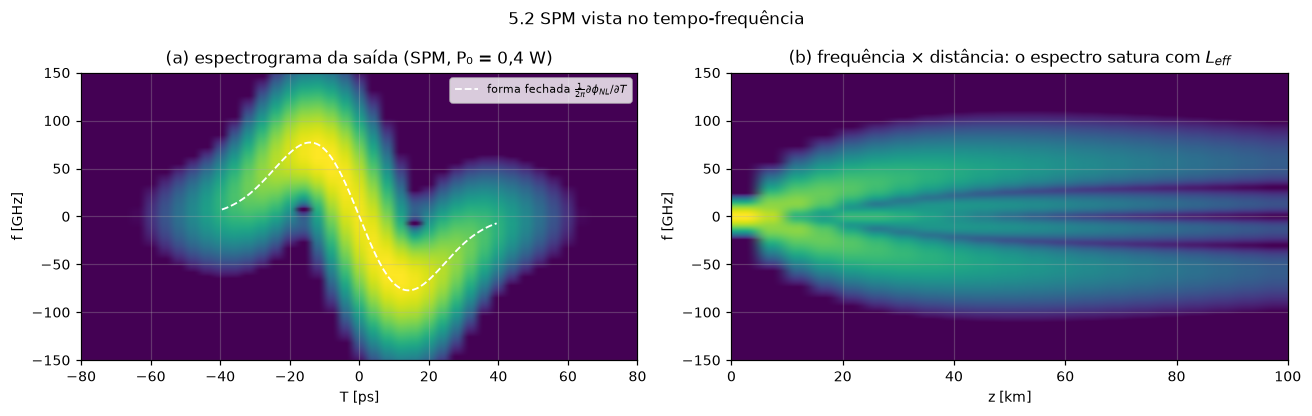

In [7]:
def espectrograma(A, t, larg=8e-12, passo=8):
    centros = t[::passo]
    w = lambda tc: np.exp(-((t - tc) / larg) ** 2)
    S = np.array([np.fft.fftshift(np.abs(np.fft.fft(A * w(tc))) ** 2) for tc in centros])
    return centros, S

P0 = 0.4
A0 = gaussiana(t, T0, P0)
s = saida_spm["amplitude ×2 (P₀ = 0,4 W)"]
tc, S = espectrograma(s, t)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ext = [tc[0] * 1e12, tc[-1] * 1e12, np.fft.fftshift(f)[0] / 1e9, np.fft.fftshift(f)[-1] / 1e9]
ax[0].imshow(10 * np.log10(S.T / S.max() + 1e-12), origin="lower", aspect="auto",
             extent=ext, vmin=-40, cmap="viridis")
finst = np.gradient(GAMMA * np.abs(A0) ** 2 * Leff, t) / (2 * np.pi)
jan = np.abs(t) < 2 * T0
ax[0].plot(t[jan] * 1e12, finst[jan] / 1e9, "w--", lw=1.2,
           label=r"forma fechada $\frac{1}{2\pi}\partial\phi_{NL}/\partial T$")
ax[0].set(xlim=(-80, 80), ylim=(-150, 150), xlabel="T [ps]", ylabel="f [GHz]",
          title="(a) espectrograma da saída (SPM, P₀ = 0,4 W)")
ax[0].legend(loc="upper right")
zmap = np.linspace(0, L5, 21)
mapa = np.array([np.fft.fftshift(np.abs(np.fft.fft(
    propagate(A0[None, :], om, fibra(z, gamma=GAMMA, alpha=ALPHA, manakov=False))[0])) ** 2)
    for z in zmap])
ax[1].imshow(10 * np.log10(mapa.T / mapa.max() + 1e-12), origin="lower", aspect="auto",
             extent=[0, L5 / 1e3, ext[2], ext[3]], vmin=-40, cmap="viridis")
ax[1].set(ylim=(-150, 150), xlabel="z [km]", ylabel="f [GHz]",
          title="(b) frequência × distância: o espectro satura com $L_{eff}$")
fig.suptitle("5.2 SPM vista no tempo-frequência")
fig.tight_layout()

**Leitura.** (a) A linha tracejada é a frequência instantânea da forma fechada e passa
pelo centro do espectrograma. (b) O alargamento é rápido no início e para de crescer
depois de alguns $L_{eff}$, porque a potência já caiu com a atenuação: a fase não
linear acumulada é $\gamma P_0 L_{eff}$, não $\gamma P_0 L$.

### 5.3 Kerr com dispersão: sóliton fundamental

Com dispersão e Kerr juntos não há forma fechada geral. A exceção é o sóliton
fundamental: em dispersão anômala (β₂ < 0), sem perda, o pulso
$A(0,T) = \sqrt{P_0}\,\mathrm{sech}(T/T_0)$ com $P_0 = |\beta_2|/(\gamma T_0^2)$ se
propaga sem mudar de forma, porque o chirp da SPM cancela o da dispersão.

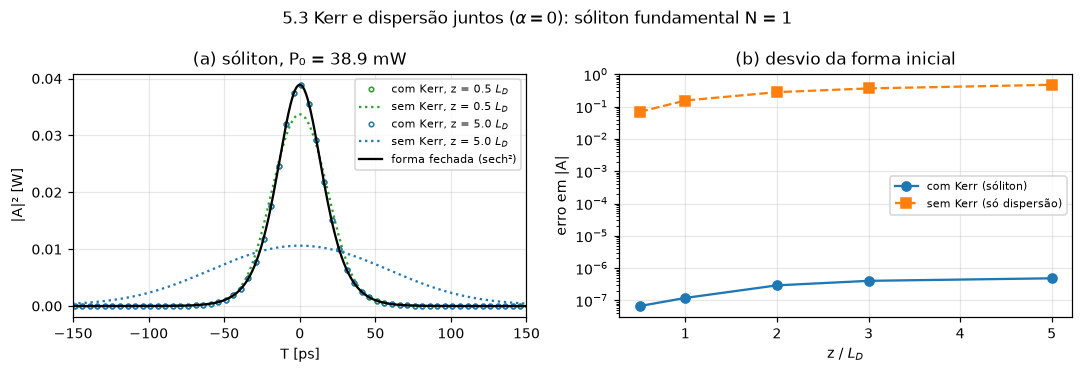

In [8]:
P_sol = abs(B2) / (GAMMA * T0 ** 2)
A_sol = np.sqrt(P_sol) / np.cosh(t / T0)
LD = T0 ** 2 / abs(B2)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
zr = np.array([0.5, 1, 2, 3, 5])
err_sol, err_lin = [], []
for i, z in enumerate(zr * LD):
    s = propagate(A_sol[None, :], om, fibra(z, beta2=B2, gamma=GAMMA, manakov=False),
                  max_step=LD / 400)[0]
    l = propagate(A_sol[None, :], om, fibra(z, beta2=B2), max_step=LD / 400)[0]
    err_sol.append(erro(np.abs(A_sol), np.abs(s)))
    err_lin.append(erro(np.abs(A_sol), np.abs(l)))
    if zr[i] in (0.5, 5):
        ax[0].plot(t[::10] * 1e12, np.abs(s[::10]) ** 2, "o", ms=3, mfc="none",
                   color=C3[0] if zr[i] == 5 else C3[2], label=f"com Kerr, z = {zr[i]} $L_D$")
        ax[0].plot(t * 1e12, np.abs(l) ** 2, ":", color=C3[0] if zr[i] == 5 else C3[2],
                   label=f"sem Kerr, z = {zr[i]} $L_D$")
ax[0].plot(t * 1e12, np.abs(A_sol) ** 2, "k-", label="forma fechada (sech²)")
ax[0].set(xlim=(-150, 150), xlabel="T [ps]", ylabel="|A|² [W]",
          title=f"(a) sóliton, P₀ = {P_sol*1e3:.1f} mW")
ax[1].semilogy(zr, err_sol, "o-", color=C3[0], label="com Kerr (sóliton)")
ax[1].semilogy(zr, err_lin, "s--", color=C3[1], label="sem Kerr (só dispersão)")
ax[1].set(xlabel="z / $L_D$", ylabel="erro em |A|", title="(b) desvio da forma inicial")
for a_ in ax: a_.legend()
fig.suptitle(r"5.3 Kerr e dispersão juntos ($\alpha = 0$): sóliton fundamental N = 1")
fig.tight_layout()

**Leitura.** Sem Kerr o mesmo pulso alarga (erro de ordem 1); com Kerr ele mantém a
forma. O erro do sóliton não é de arredondamento: é o erro de separação do split-step,
que existe quando dispersão e Kerr atuam juntos e diminui com o passo (seção 6).

Testes que garantem: `test_03_nao_linearidade.py` (SPM, 8/9) e `test_05_soliton.py`.

### 5.4 Mistura de quatro ondas (FWM)

**Conceito.** Com dois tons em $f_1$ e $f_2$, o termo $|A|^2A$ contém produtos
$A_1^2A_2^*$, que oscilam em $2f_1-f_2$: o Kerr cria frequências novas. Esses produtos
misturam de novo com os tons originais e geram $3f_1-2f_2$, e assim por diante (cascata).

**Forma fechada** (pequeno sinal, sem perda, escalar):

$$P_{2f_1-f_2}(L) = \gamma^2 P_1^2 P_2\,L^2\,\mathrm{sinc}^2\!\left(\frac{\Delta\beta L}{2}\right),
\qquad \Delta\beta = \beta_2\,(2\pi\,\Delta f)^2,\quad \mathrm{sinc}(x) = \frac{\sin x}{x}$$

Sem dispersão (Δβ = 0) a componente nova cresce com $L^2$. Com dispersão, as ondas
perdem a relação de fase depois do comprimento de coerência $2\pi/\Delta\beta$: a energia
vai e volta e não se acumula. Com pulsos o efeito equivalente é a separação temporal:
canais em frequências diferentes viajam com velocidades de grupo diferentes e, quando
os pulsos deixam de se sobrepor, a FWM para de ser gerada.

A aproximação de pequeno sinal despreza a fase da SPM/XPM dos próprios tons; o erro
relativo resultante cresce como $(\gamma P L)^2$, o que o painel (c) mostra.

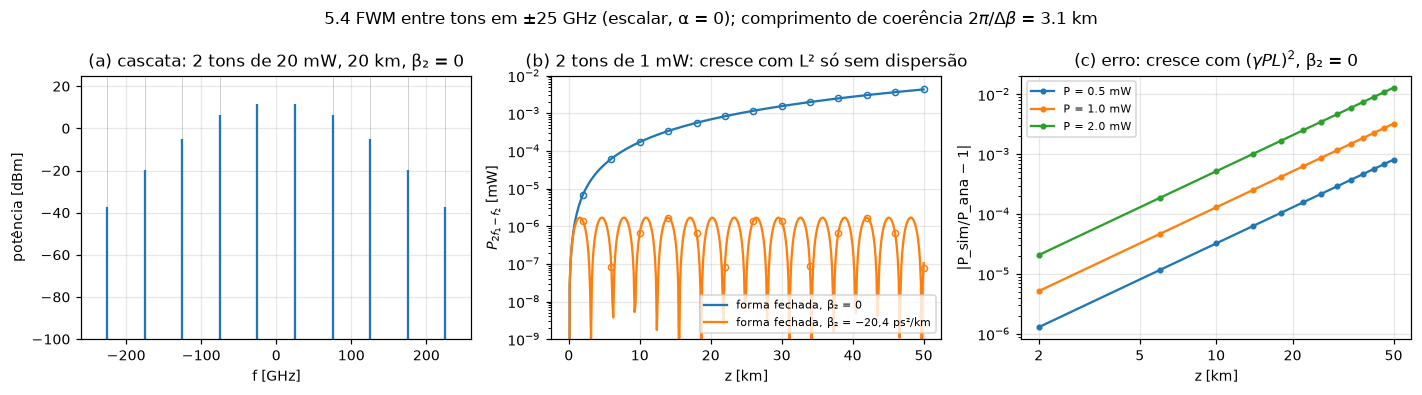

In [9]:
Nf, FSf = 2 ** 10, 1.024e12                     # resolução de 1 GHz: tons em bins exatos
tf, ff, omf = grade(Nf, FSf)
f1, f2 = -25e9, 25e9
k3 = np.argmin(np.abs(ff - (2 * f1 - f2)))
tons = lambda P: (np.sqrt(P) * np.exp(2j * np.pi * f1 * tf)
                  + np.sqrt(P) * np.exp(2j * np.pi * f2 * tf))
pot = lambda A, k: np.abs(np.fft.fft(A)[k] / Nf) ** 2
dbeta = abs(B2) * (2 * np.pi * (f2 - f1)) ** 2
zf = np.linspace(2e3, 50e3, 13)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
# (a) cascata
s = propagate(tons(20e-3)[None, :], omf, fibra(20e3, gamma=GAMMA, manakov=False),
              max_step=100.0)[0]
Sp = np.abs(np.fft.fftshift(np.fft.fft(s)) / Nf) ** 2
ax[0].stem(np.fft.fftshift(ff) / 1e9, 10 * np.log10(Sp * 1e3 + 1e-30), bottom=-120,
           markerfmt=" ", basefmt=" ")
for m in range(1, 5):
    ax[0].axvline(((m + 1) * f1 - m * f2) / 1e9, color="0.8", lw=0.6, zorder=0)
    ax[0].axvline(((m + 1) * f2 - m * f1) / 1e9, color="0.8", lw=0.6, zorder=0)
ax[0].set(xlim=(-260, 260), ylim=(-100, 25), xlabel="f [GHz]", ylabel="potência [dBm]",
          title="(a) cascata: 2 tons de 20 mW, 20 km, β₂ = 0")
# (b) crescimento com e sem dispersão
for i, (b2, nome) in enumerate([(0.0, "β₂ = 0"), (B2, "β₂ = −20,4 ps²/km")]):
    db = abs(b2) * (2 * np.pi * (f2 - f1)) ** 2
    zz = np.linspace(0, 50e3, 400)
    ana = GAMMA ** 2 * 1e-3 ** 3 * zz ** 2 * np.sinc(db * zz / 2 / np.pi) ** 2
    simf = [pot(propagate(tons(1e-3)[None, :], omf, fibra(z, beta2=b2, gamma=GAMMA,
                                                          manakov=False), max_step=100.0)[0], k3)
            for z in zf]
    ax[1].semilogy(zz / 1e3, ana * 1e3 + 1e-30, "-", color=C3[i], label=f"forma fechada, {nome}")
    ax[1].semilogy(zf / 1e3, np.array(simf) * 1e3, "o", ms=4, mfc="none", color=C3[i])
ax[1].set(ylim=(1e-9, 1e-2), xlabel="z [km]", ylabel=r"$P_{2f_1-f_2}$ [mW]",
          title="(b) 2 tons de 1 mW: cresce com L² só sem dispersão")
# (c) erro da aproximação de pequeno sinal
for i, P in enumerate([0.5e-3, 1e-3, 2e-3]):
    e = [abs(pot(propagate(tons(P)[None, :], omf, fibra(z, gamma=GAMMA, manakov=False),
                           max_step=100.0)[0], k3)
             / (GAMMA ** 2 * P ** 3 * z ** 2) - 1) for z in zf]
    ax[2].loglog(zf / 1e3, e, "o-", ms=3, color=C3[i], label=f"P = {P*1e3:.1f} mW")
eixo_log_legivel(ax[2], [2, 5, 10, 20, 50])
ax[2].set(xlabel="z [km]", ylabel="|P_sim/P_ana − 1|",
          title=r"(c) erro: cresce com $(\gamma P L)^2$, β₂ = 0")
for a_ in ax[1:]: a_.legend()
fig.suptitle(rf"5.4 FWM entre tons em ±25 GHz (escalar, α = 0); comprimento de coerência "
             rf"$2\pi/\Delta\beta$ = {2*np.pi/dbeta/1e3:.1f} km")
fig.tight_layout()

**Leitura.** (a) Os produtos aparecem nas posições previstas (linhas cinzas) e caem em
potência a cada ordem da cascata. (b) Sem dispersão a componente cresce com $L^2$; com a
dispersão da fibra padrão ela oscila com período igual ao comprimento de coerência e
fica ordens de grandeza abaixo. É por isso que a FWM pesa pouco em fibra padrão e muito
em fibra de dispersão deslocada. (c) O erro escala com o quadrado da potência e da
distância, como esperado da aproximação.

Pendência registrada: o arquivo VPI de referência tem `FWM = No`, e o SSFM de campo
agregado não tem como desligar a FWM (decisão aberta D-21).

Separação temporal de pulsos (o caso da aula com pulsos em vez de tons): sem forma
fechada; fica como próximo passo deste notebook.

## 6. Todos os efeitos juntos

Com α, β₂, γ e PMD ligados não há forma fechada para o campo. Duas propriedades
continuam exatas:

1. **Energia.** Dispersão, Kerr e PMD conservam energia; só a atenuação a retira. Dessa
   forma $E(L) = E(0)\,e^{-\alpha L}$ vale com todos os termos ligados.
2. **Ordem de convergência.** O split-step simétrico tem erro global proporcional a
   $h^2$ (h = passo). Comparando com uma referência de passo muito pequeno, o erro deve
   cair 4× quando o passo cai 2×.

A convergência é medida sem PMD: a realização sorteada depende da sequência de passos,
então mudar o passo muda a realização e a comparação deixa de fazer sentido.

E(L)/E(0) = 0.025118864315  |  e^(-αL) = 0.025118864315  |  erro relativo = 3.2e-14


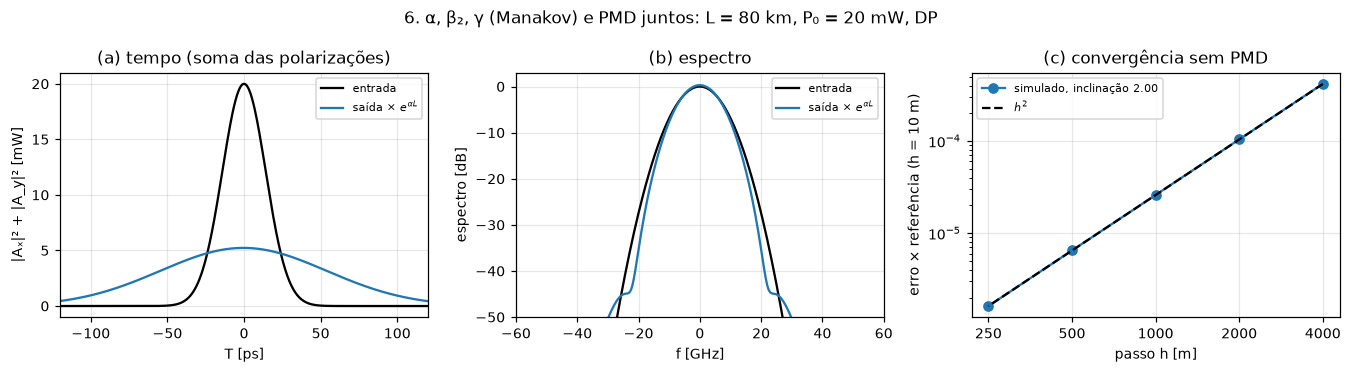

In [10]:
P0 = 20e-3
A6 = np.vstack([gaussiana(t, T0, P0)] * 2) / np.sqrt(2)
L6 = 80e3
tudo = fibra(L6, beta2=B2, gamma=GAMMA, alpha=ALPHA, pmd_coefficient=0.1e-12 / np.sqrt(1e3))
s6 = propagate(A6, om, tudo, rng=np.random.default_rng(3))
print(f"E(L)/E(0) = {energia(s6, dt)/energia(A6, dt):.12f}  |  "
      f"e^(-αL) = {np.exp(-ALPHA*L6):.12f}  |  erro relativo = "
      f"{abs(energia(s6, dt)/energia(A6, dt)/np.exp(-ALPHA*L6) - 1):.1e}")

sem_pmd = fibra(L6, beta2=B2, gamma=GAMMA, alpha=ALPHA)
ref = propagate(A6, om, sem_pmd, max_step=10.0, max_phase_deg=1e9)
hs = np.array([4000, 2000, 1000, 500, 250])
errs = [erro(ref, propagate(A6, om, sem_pmd, max_step=h, max_phase_deg=1e9)) for h in hs]
inc = np.polyfit(np.log(hs), np.log(errs), 1)[0]

fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.4))
ax[0].plot(t * 1e12, np.sum(np.abs(A6) ** 2, axis=0) * 1e3, "k-", label="entrada")
ax[0].plot(t * 1e12, np.sum(np.abs(s6) ** 2, axis=0) * 1e3 / np.exp(-ALPHA * L6), "-",
           color=C3[0], label="saída × $e^{\\alpha L}$")
ax[0].set(xlim=(-120, 120), xlabel="T [ps]", ylabel="|Aₓ|² + |A_y|² [mW]",
          title="(a) tempo (soma das polarizações)")
Sin = np.fft.fftshift(np.sum(np.abs(np.fft.fft(A6, axis=1)) ** 2, axis=0))
Sout = np.fft.fftshift(np.sum(np.abs(np.fft.fft(s6, axis=1)) ** 2, axis=0))
ax[1].plot(np.fft.fftshift(f) / 1e9, 10 * np.log10(Sin / Sin.max() + 1e-30), "k-",
           label="entrada")
ax[1].plot(np.fft.fftshift(f) / 1e9,
           10 * np.log10(Sout / Sin.max() / np.exp(-ALPHA * L6) + 1e-30),
           "-", color=C3[0], label="saída × $e^{\\alpha L}$")
ax[1].set(xlim=(-60, 60), ylim=(-50, 3), xlabel="f [GHz]", ylabel="espectro [dB]",
          title="(b) espectro")
ax[2].loglog(hs, errs, "o-", color=C3[0], label=f"simulado, inclinação {inc:.2f}")
ax[2].loglog(hs, errs[-1] * (hs / hs[-1]) ** 2, "k--", label="$h^2$")
eixo_log_legivel(ax[2], hs)
ax[2].set(xlabel="passo h [m]", ylabel="erro × referência (h = 10 m)",
          title="(c) convergência sem PMD")
for a_ in ax: a_.legend()
fig.suptitle("6. α, β₂, γ (Manakov) e PMD juntos: L = 80 km, P₀ = 20 mW, DP")
fig.tight_layout()

**Leitura.** A energia segue $e^{-\alpha L}$ no arredondamento mesmo com todos os efeitos
ligados. O erro cai com inclinação próxima de 2, a ordem do split-step simétrico; uma
inclinação próxima de 1 indicaria o esquema assimétrico (mutação 6 do
`scripts/mutacoes.py`).

Testes que garantem: `test_05_soliton.py` (ordem de convergência) e os testes de
conservação de energia.